In [2]:
from lib.dataset import discover_samples, EuroSATDataset
from lib.constants import CLASSES, NUM_CLASSES, NUM_BANDS
RANDOM_STATE = 42

In [10]:
from lib.splits import make_stratified_splits

samples = discover_samples()
d = make_stratified_splits(samples, val_ratio=0.15, test_ratio=0.15, seed=RANDOM_STATE)

for split in ("train", "val", "test"):
    samples = d[split]
    counts = [0] * NUM_CLASSES
    for _, label in samples:
        counts[label] += 1

    print(f"{split}: {len(samples)} samples")
    for cls_name, cnt in zip(CLASSES, counts):
        print(f"  {cls_name}: {cnt}")
    print()

train: 18899 samples
  AnnualCrop: 2100
  Forest: 2100
  HerbaceousVegetation: 2099
  Highway: 1750
  Industrial: 1750
  Pasture: 1400
  PermanentCrop: 1750
  Residential: 2100
  River: 1750
  SeaLake: 2100

val: 4051 samples
  AnnualCrop: 450
  Forest: 450
  HerbaceousVegetation: 451
  Highway: 375
  Industrial: 375
  Pasture: 300
  PermanentCrop: 375
  Residential: 450
  River: 375
  SeaLake: 450

test: 4050 samples
  AnnualCrop: 450
  Forest: 450
  HerbaceousVegetation: 450
  Highway: 375
  Industrial: 375
  Pasture: 300
  PermanentCrop: 375
  Residential: 450
  River: 375
  SeaLake: 450



# Load Torchvision model

Im using imagenet as a first try

In [73]:
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn.functional as F
import torch
from lib.constants import NUM_CLASSES, S2_REFLECTANCE_SCALE

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# TODO i need to create a transformation function that normalizes the rgb data to be usable for imagenet
def imagenet_transform(t):
    t = t / S2_REFLECTANCE_SCALE
    t = F.interpolate(t.unsqueeze(0), size=224, mode="bilinear", align_corners=False).squeeze(0)
    t = (t - IMAGENET_MEAN) / IMAGENET_STD    # ImageNet normalization
    return t                                  # (3, 224, 22

model = resnet18(weights=ResNet18_Weights.DEFAULT)

In [77]:
from torch.utils.data import DataLoader

train = EuroSATDataset(d['train'], transform=imagenet_transform, rgb_only=True)
test = EuroSATDataset(d['test'], transform=imagenet_transform, rgb_only=True)
val = EuroSATDataset(d['val'], transform=imagenet_transform, rgb_only=True)

train_dl = DataLoader(train, batch_size=64, shuffle=True, num_workers=0)
test_dl = DataLoader(test, batch_size=64, shuffle=True, num_workers=0)
val_dl = DataLoader(val, batch_size=64, shuffle=True, num_workers=0)


In [78]:
model.fc = torch.nn.Linear(model.fc.in_features, NUM_CLASSES)

for p in model.parameters():
    p.requires_grad = False # Stop learning in the resnet pretrained model
for p in model.fc.parameters():
    p.requires_grad = True

device = "mps"
model = model.to(device)

In [82]:
import time

loss_fn = torch.nn.CrossEntropyLoss()
learning_rate=1e-3

optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=learning_rate
)

EPOCHS = 5

print("Starting Training")
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    for imgs, labels in train_dl:
        imgs, labels = imgs.to(device), labels.to(device)

        preds = model(imgs)
        loss = loss_fn(preds, labels)
        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
    train_loss /= len(train_dl.dataset)


    # validate

    model.eval()
    correct = total = 0
    with torch.no_grad():
        for imgs, labels in val_dl:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs).argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    val_acc = correct / total

    print(f"epoch {epoch+1}/{EPOCHS} train_loss={train_loss:.4f} val_acc={val_acc:.4f} time={epoch_time:.2f}s")
    

KeyboardInterrupt: 

# Sanity check: visualize a tensor image

Pull a sample straight out of the `Dataset` and render its natural-color RGB
composite. This confirms the bands are in the order we think (R=B04, G=B03,
B=B02) and that the tensor reaching the model actually looks like the labelled
class. Raw Sentinel-2 reflectance is very dark, so we apply a percentile
contrast stretch purely for display — this does **not** touch what the model sees.

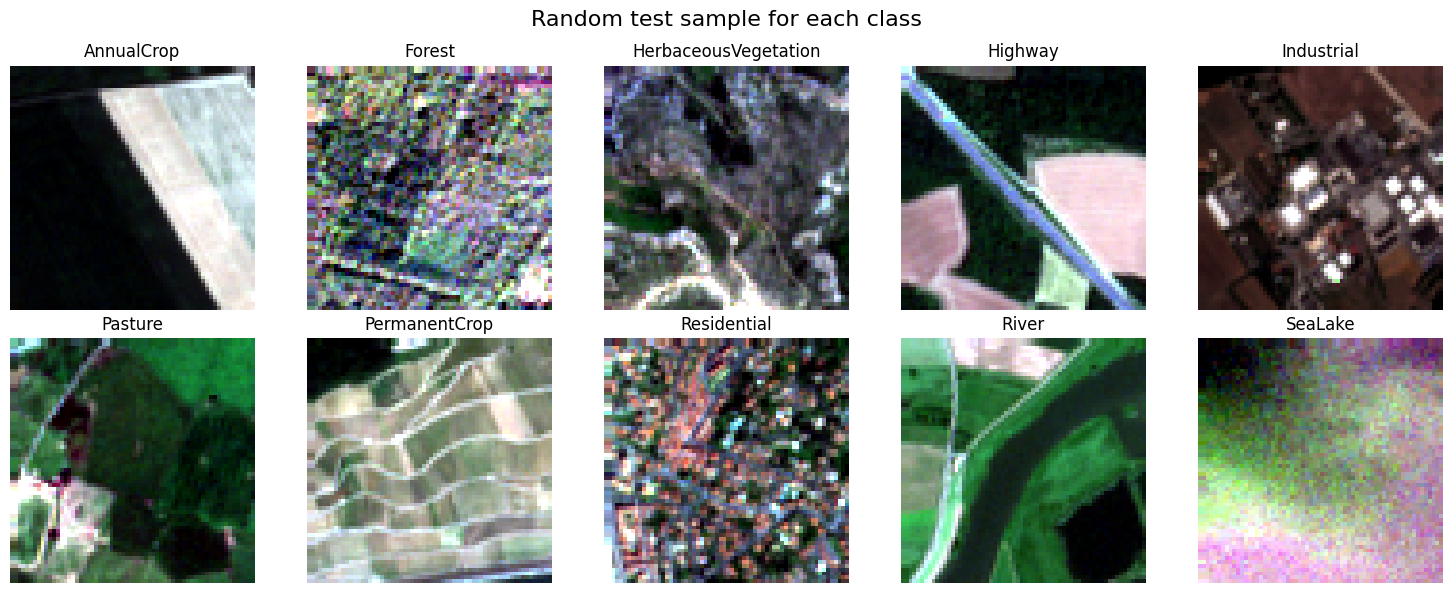

In [65]:
import random
import numpy as np
import matplotlib.pyplot as plt
from lib.constants import CLASSES, RGB_BAND_INDICES

# ! AI Generated Helper Function
def show_tensor_image(tensor, label=None, ax=None):
    """Render the RGB composite of a (C, H, W) EuroSAT tensor.

    Accepts either a 3-channel RGB tensor (already R, G, B -- e.g. from
    `EuroSATDataset(..., rgb_only=True)`) or the full 13-band sample, in
    which case the RGB bands are selected. A 2-98 percentile stretch is
    applied *per channel* for display only: EuroSAT is Sentinel-2 L1C
    (top-of-atmosphere), where the blue band is lifted by atmospheric
    scattering, so a per-channel stretch removes the blue cast that would
    otherwise make forest/water look blue.
    """
    if tensor.shape[0] == 3:                        # already RGB
        rgb = tensor
    else:                                           # full 13-band -> pick RGB
        rgb = tensor[list(RGB_BAND_INDICES)]        # (3, H, W) in R, G, B order
    rgb = rgb.detach().cpu().float().permute(1, 2, 0).numpy()  # (H, W, 3)

    lo, hi = np.percentile(rgb, (2, 98), axis=(0, 1))  # per-channel -> shape (3,)
    rgb = np.clip((rgb - lo) / (hi - lo + 1e-8), 0, 1)

    ax = ax or plt.subplots(figsize=(3, 3))[1]
    ax.imshow(rgb)
    ax.set_axis_off()
    if label is not None:
        ax.set_title(CLASSES[label] if isinstance(label, int) else label)
    return ax


label_to_indices = {label: [] for label in range(NUM_CLASSES)}
for idx, (_, lbl) in enumerate(test):
    label_to_indices[lbl].append(idx)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for label in range(NUM_CLASSES):
    idx = random.choice(label_to_indices[label])
    img, label = test[idx]
    show_tensor_image(img, label, ax=axes[label])

fig.suptitle("Random test sample for each class", fontsize=16)
fig.tight_layout()